# The O+O hadron files, read from the OSDF

The analysis half of `oo_workflow.ipynb`, on its hadron files as they are kept on the OSDF:
**3 O+O events at 200 GeV** (3dMCGlauber, PythiaIsrGun + iMATTER, MUSIC, Matter + LBT,
iColoredHadronization, iSS with 20 oversamples), written by that notebook and uploaded to the
public Pelican namespace `osdf:///fno4hic`:

```
osdf:///fno4hic/test/OO_test/
    OO_workflow_hadrons_bulk_bg.h5     1.1 MB   iSS, 20 oversamples per event
    OO_workflow_hadrons_jet_frag.h5    381 kB   iColoredHadronization, one per event
    oo_workflow.xml                    7.7 kB   the run's user XML
```

The files are **streamed**: pelicanfs (an fsspec file system) finds an OSDF cache for the path
and h5py reads the file object by byte ranges, so nothing is written to disk. Reading
`/fno4hic` is public: no account, login or token.

| section | |
|---|---|
| 1 Setup | the OSDF file system, the files |
| 2 The job | the run's settings, from its XML on the OSDF |
| 3 Read the hadron files | `HadronArray.from_h5()` on a streamed file, the units table, the shower initiators |
| 4 Nested views | `to_awkward()`, `vector` kinematics, `js.select()` |
| 5 Spectra | the pT spectra as `hist` histograms with event-to-event errors (`mplhep`) |
| 6 Jets | FastJet on the jagged arrays; a jet embedded in the bulk |

**Needs** only the analysis env, no X-SCAPE build: `utils/analysis_env/setup_analysis_env.sh`
(pelicanfs is in it by default; `--no-pelican` leaves it out, then use downloaded files, below).
`jetscape` is imported from `contribs/PyJetscape/python`, without `pyjetscape_core`.

**To download the files instead** (for reading them more than once, or offline), and set
`OO_DIR` to the directory they are in; the notebook then reads them from there:

- with the command-line tool in `utils/remote_transfer` (it makes its own Python environment
  on the first run; `utils/remote_transfer/README.md`):

  ```bash
  cd js-contrib/utils/remote_transfer
  ./js_osdf.py ls test/OO_test                          # the files and their sizes
  ./js_osdf.py download test/OO_test --to ~/data         # -> ~/data/OO_test/
  ```

- or from Python, in this env: `fsspec.filesystem("osdf").get("/fno4hic/test/OO_test/",
  "OO_test/", recursive=True)` (cell 1 has it, commented out).

Then `OO_DIR=~/data/OO_test jupyter lab`, or set `OO_DIR` in cell 1.

## 1 Setup

In [1]:
import os
import sys
from pathlib import Path

import fsspec
import numpy as np

NB_DIR = Path.cwd()                                  # example/pythonic
sys.path.insert(0, str(NB_DIR.parents[1] / "python"))  # contribs/PyJetscape/python
import jetscape as js                                # HadronArray, to_awkward, select: no build

REMOTE = "/fno4hic/test/OO_test"                     # osdf:///fno4hic/test/OO_test, public
OO_DIR = os.environ.get("OO_DIR")                    # a directory of downloaded files, else stream
STEM = "OO_workflow"
bulk_name = STEM + "_hadrons_bulk_bg.h5"             # iSS, N_OVERSAMPLE samples per event
jet_name = STEM + "_hadrons_jet_frag.h5"             # iColoredHadronization, one per event

fs = fsspec.filesystem("osdf")                       # pelicanfs; the first request finds a cache


def open_file(name):
    # a file of the run: the downloaded copy in OO_DIR, else streamed from the OSDF. 1 MB
    # blocks: HDF5 jumps back to its metadata, which the default read-ahead fetches again
    if OO_DIR:
        return open(Path(OO_DIR).expanduser() / name, "rb")
    return fs.open(f"{REMOTE}/{name}", "rb", cache_type="blockcache", block_size=2**20)


# to download the files once instead (or: utils/remote_transfer/js_osdf.py download test/OO_test)
# fs.get(REMOTE + "/", "OO_test/", recursive=True); OO_DIR = "OO_test"

if OO_DIR:
    print("local:", OO_DIR)
else:
    for f in fs.ls(REMOTE, detail=True):
        if not f["name"].rsplit("/", 1)[-1].startswith("."):   # not js_osdf.py's manifest
            print(f"{f['size'] / 1e3:9.1f} kB  osdf://{f['name']}")

    380.7 kB  osdf:///fno4hic/test/OO_test/OO_workflow_hadrons_jet_frag.h5
      7.7 kB  osdf:///fno4hic/test/OO_test/oo_workflow.xml
   1142.0 kB  osdf:///fno4hic/test/OO_test/OO_workflow_hadrons_bulk_bg.h5


## 2 The job

The run's user XML is stored next to its hadron files; the cell reads the settings back from it,
as `oo_workflow.ipynb` does: 3 events, seed 7, pTHat 20-40 GeV with both hard partons at
|y| < 0.6, Matter + LBT, iColored with the `reconnect` colour closure, iSS with 20 oversamples.

In [2]:
import xml.etree.ElementTree as ET

with open_file("oo_workflow.xml") as fo:
    root = ET.parse(fo).getroot()
N_EVENTS = int(root.findtext("nEvents"))
N_OVERSAMPLE = int(root.findtext("SoftParticlization/iSS/number_of_repeated_sampling"))
mcg, gun = root.find("IS/MCGlauber"), root.find("Hard/PythiaGun")
print(f"{mcg.findtext('projectile').strip()}+{mcg.findtext('target').strip()} "
      f"{float(mcg.findtext('sqrts')):g} GeV, b {mcg.findtext('b_min').strip()}-"
      f"{mcg.findtext('b_max').strip()} fm, {N_EVENTS} events, seed "
      f"{root.findtext('Random/seed').strip()}")
print(f"pTHat {gun.findtext('pTHatMin').strip()}-{gun.findtext('pTHatMax').strip()} GeV, "
      f"hard partons |y| < {gun.findtext('partonYMax').strip()}")
print("energy loss:", [c.tag for c in root.find("Eloss") if c.tag in ("Matter", "Lbt")],
      "| colour closure:", root.findtext("JetHadronization/colour_closure"),
      "| iSS oversamples:", N_OVERSAMPLE)

O+O 200 GeV, b 0.0-3.0 fm, 3 events, seed 7
pTHat 20-40 GeV, hard partons |y| < 0.6
energy loss: ['Matter', 'Lbt'] | colour closure: reconnect | iSS oversamples: 20


## 3 Read the hadron files

`HadronArray.from_h5` takes a path or an open file object, so it reads the streamed file as it
reads a local one: the stored fields as they are (float32, no derived columns);
`info["unit_offsets"]` groups the samples into units (events) and `info["units"]` is each
unit's record: the event, its seeds, pTHat, the Glauber numbers, the colour audit. The shower
initiators (the hard partons that started the showers) are stored with the jet file; they are
read here, while the file is open.

In [3]:
import time

import h5py
import pandas as pd
from jetscape.records import initiator_records

t0 = time.time()
with open_file(jet_name) as fo:
    jet_h = js.HadronArray.from_h5(fo)
    with h5py.File(fo, "r") as f:                    # the shower initiators, one table per event
        ini_rows, ini_off = f["initiators/data"][()], f["initiators/offsets"][()]
with open_file(bulk_name) as fo:
    bulk_h = js.HadronArray.from_h5(fo)
print(jet_h, "|", bulk_h, f"| read in {time.time() - t0:.1f} s")
print("bulk oversamples per event:", bulk_h.info["attrs"]["n_samples"],
      "| units:", jet_h.info["attrs"]["units"])
units = pd.DataFrame(jet_h.info["units"])
units[["event", "pthat", "glauber_npart", "glauber_ncoll", "glauber_b", "seed",
       "colour_holes", "colour_partners", "colour_reconnected"]].set_index("event")

HadronArray(400 hadrons in 3 samples) | HadronArray(22181 hadrons in 60 samples) | read in 0.3 s
bulk oversamples per event: 20 | units: p in GeV; x in fm (t in fm/c)


,pthat,glauber_npart,glauber_ncoll,glauber_b,seed,colour_holes,colour_partners,colour_reconnected
event,,,,,,,,
0,20.631801,24,26,1.87951,1820204315,5,1,2
1,26.509517,20,22,1.71783,2006610252,11,2,5
2,22.852107,14,19,2.91757,293415080,4,1,1


## 4 Nested views

`to_awkward()` builds the nested view over the same buffers: the jet file is
**events x hadrons** (one sample per event); `by_unit=True` makes the bulk file
**events x oversamples x hadrons**. `js.select` takes PDG names or classes
(`"charged"`, `"baryon"`, `"pi+"`, ...).

In [4]:
import awkward as ak

jets_had = jet_h.to_awkward()                    # events x hadrons
bulk_had = bulk_h.to_awkward(by_unit=True)       # events x oversamples x hadrons

charged_jet = jets_had[js.select(jets_had, "charged")]
charged_bulk = bulk_had[js.select(bulk_had, "charged")]
print("jet hadrons per event:", ak.num(jets_had).tolist(),
      "| charged:", ak.num(charged_jet).tolist())
print("bulk hadrons per oversample, mean per event:",
      np.round(ak.to_numpy(ak.mean(ak.num(bulk_had, axis=2), axis=1)), 1).tolist())
protons = js.select(bulk_had, ["p", "p~"])                 # events x oversamples x hadrons
print("protons + antiprotons per oversample, mean per event:",
      np.round(ak.to_numpy(ak.mean(ak.sum(protons, axis=2), axis=1)), 1).tolist())
mid = abs(charged_bulk.eta) < 0.5                          # |eta| < 0.5: d(eta) = 1
print("bulk dN_ch/deta at |eta| < 0.5, per event:",
      np.round(ak.to_numpy(ak.mean(ak.sum(mid, axis=2), axis=1)), 1).tolist())

jet hadrons per event: [78, 174, 148] | charged: [33, 69, 61]
bulk hadrons per oversample, mean per event: [392.6, 438.8, 277.6]
protons + antiprotons per oversample, mean per event: [14.8, 18.0, 12.5]
bulk dN_ch/deta at |eta| < 0.5, per event: [21.2, 33.2, 21.3]


## 5 Spectra

The charged-hadron pT spectra at |η| < 1, with statistical errors, using `hist`
(boost-histogram) and `mplhep`:

- one histogram per event: the jet hadrons of the event, and the bulk hadrons of its
  oversamples, each weighted 1/N_oversamples (so it is that event's mean spectrum);
- the points are the mean over the events, the error bars the **event-to-event** standard
  error, std / √N_events.

Why not the histogram's own √Σw²: for the jet hadrons each event is one independent sample,
so √Σw² would be about right. The bulk's oversamples of one event all sample the same hydro
event: √Σw² counts them as independent and gives the sampling noise only, without the
event-to-event fluctuations (the events differ by ~60 % in multiplicity here). The cell
prints how much smaller it is. With 3 events the errors are large: this shows the method,
not a measurement.

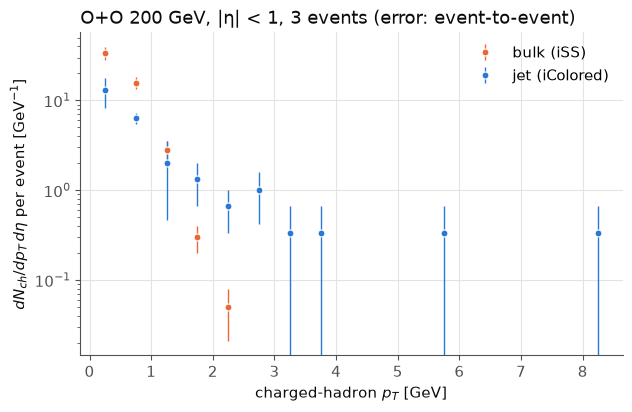

bulk: event-to-event error / sqrt(sum w^2), per pT bin:
   0.0- 0.5 GeV:   7.4
   0.5- 1.0 GeV:   4.7
   1.0- 1.5 GeV:   3.3
   1.5- 2.0 GeV:   1.4
   2.0- 2.5 GeV:   1.0


In [5]:
import hist
import matplotlib.pyplot as plt
import mplhep

BLUE, ORANGE = "#2a78d6", "#eb6834"            # categorical slots 1 and 2
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

PT = hist.axis.Regular(20, 0.0, 10.0, name="pt", label="charged-hadron $p_T$ [GeV]")
DETA = 2.0                                       # |eta| < 1


def event_spectrum(pt, weight=1.0):
    # one event's dN/dpT deta as a weighted histogram (sum of w and of w^2 per bin)
    h = hist.Hist(PT, storage=hist.storage.Weight())
    h.fill(pt=pt, weight=np.full(len(pt), weight / DETA))
    return h / PT.widths


jet_ev, bulk_ev = [], []
for e in range(n_ev := len(jet_h.info["units"]["event"])):
    j = charged_jet[e]
    jet_ev.append(event_spectrum(ak.to_numpy(j.pt[abs(j.eta) < 1])))
    b = charged_bulk[e]                                         # oversamples x hadrons
    n_os = len(b)
    bulk_ev.append(event_spectrum(ak.to_numpy(ak.flatten(b.pt[abs(b.eta) < 1])), 1.0 / n_os))


def mean_and_error(hists):
    v = np.array([h.values() for h in hists])
    return v.mean(axis=0), v.std(axis=0, ddof=1) / np.sqrt(len(hists))


fig, ax = plt.subplots(figsize=(7, 4.2))
for hists, color, label in ((bulk_ev, ORANGE, "bulk (iSS)"), (jet_ev, BLUE, "jet (iColored)")):
    mean, err = mean_and_error(hists)
    filled = mean > 0                               # empty bins have no point on a log axis
    mplhep.histplot(np.where(filled, mean, np.nan), PT.edges, yerr=np.where(filled, err, 0),
                    histtype="errorbar", color=color, label=label, ax=ax,
                    marker="o", markersize=5, mec="white", mew=0.8, capsize=0)
ax.set_yscale("log")
ax.set_xlabel(PT.label)
ax.set_ylabel(r"$dN_{ch}/dp_T\,d\eta$ per event [GeV$^{-1}$]")
ax.set_title(f"O+O 200 GeV, |η| < 1, {n_ev} events (error: event-to-event)", color=INK,
             loc="left")
ax.legend(frameon=False)
plt.show()

# the bulk's sqrt(sum w^2), summed over the events, against the event-to-event error
total = sum(bulk_ev[1:], bulk_ev[0])
sampling = np.sqrt(total.variances()) / n_ev
_, between = mean_and_error(bulk_ev)
print("bulk: event-to-event error / sqrt(sum w^2), per pT bin:")
for lo, hi, a, b in zip(PT.edges[:-1], PT.edges[1:], between, sampling):
    if b > 0:
        print(f"  {lo:4.1f}-{hi:4.1f} GeV: {a / b:5.1f}")

## 6 Jets with FastJet

FastJet's Python package takes the jagged awkward arrays directly: **one call clusters every
event** (or every oversample). Anti-kt, R = 0.4, hadrons at |η| < 2.

First the jets of the jet hadrons, all and charged only; the jets sit close to the hard
partons that started them (the initiators read in section 3).

In [6]:
import fastjet

jdef = fastjet.JetDefinition(fastjet.antikt_algorithm, 0.4)
acc = jets_had[abs(jets_had.eta) < 2]
jets_all = fastjet.ClusterSequence(acc, jdef).inclusive_jets(min_pt=5.0)
jets_ch = fastjet.ClusterSequence(acc[js.select(acc, "charged")], jdef).inclusive_jets(min_pt=3.0)
jets_all = jets_all[ak.argsort(jets_all.pt, ascending=False)]
jets_ch = jets_ch[ak.argsort(jets_ch.pt, ascending=False)]

rows = []
for e in range(n_ev):
    ini = initiator_records(ini_rows[ini_off[e]:ini_off[e + 1]])
    hard = np.sort(np.hypot(ini["px"], ini["py"]))[::-1][:2]
    rows.append({"event": int(jet_h.info["units"]["event"][e]),
                 "hard partons pT": np.round(hard, 1).tolist(),
                 "jets pT (all)": np.round(ak.to_numpy(jets_all[e].pt), 1).tolist(),
                 "jets pT (charged)": np.round(ak.to_numpy(jets_ch[e].pt), 1).tolist()})
pd.DataFrame(rows).set_index("event")

#--------------------------------------------------------------------------
#                         FastJet release 3.5.2
#                 M. Cacciari, G.P. Salam and G. Soyez                  
#     A software package for jet finding and analysis at colliders      
#                           https://fastjet.fr                           
#	                                                                      
# Please cite EPJC72(2012)1896 [arXiv:1111.6097] if you use this package
# for scientific work and optionally PLB641(2006)57 [hep-ph/0512210].   
#                                                                       
# FastJet is provided without warranty under the GNU GPL v2 or higher.  
# It uses T. Chan's closest pair algorithm, S. Fortune's Voronoi code,
# CGAL and 3rd party plugin jet algorithms. See COPYING file for details.
#--------------------------------------------------------------------------


,hard partons pT,jets pT (all),jets pT (charged)
event,,,
0,"[22.3, 19.1]","[21.2, 15.4]","[5.0, 4.2]"
1,"[26.8, 26.3]","[23.5, 13.0]","[9.8, 5.8, 4.8]"
2,"[22.9, 22.9]","[20.7, 20.0]",[16.9]


Then the bulk: **every oversample of every event** clustered at once
(events x oversamples x hadrons, flattened to oversamples x hadrons), giving the jets the
underlying event alone makes. And a jet **embedded in the bulk**: each event's jet hadrons
added to its first oversample, so the leading jet picks up the background under it.

In [7]:
flat_bulk = ak.flatten(bulk_had, axis=1)                       # all oversamples
flat_bulk = flat_bulk[abs(flat_bulk.eta) < 2]
bulk_jets = fastjet.ClusterSequence(flat_bulk, jdef).inclusive_jets(min_pt=5.0)
print(f"bulk alone: {len(flat_bulk)} oversamples, "
      f"{float(ak.mean(ak.num(bulk_jets))):.2f} jets > 5 GeV per oversample")

embedded = ak.concatenate([jets_had, bulk_had[:, 0]], axis=1)  # jet + one oversample
embedded = embedded[abs(embedded.eta) < 2]
emb_jets = fastjet.ClusterSequence(embedded, jdef).inclusive_jets(min_pt=5.0)
lead_emb = ak.to_numpy(ak.max(emb_jets.pt, axis=1))
lead_jet = ak.to_numpy(ak.fill_none(ak.max(jets_all.pt, axis=1), 0.0))
pd.DataFrame({"event": jet_h.info["units"]["event"],
              "leading jet pT, jet hadrons": np.round(lead_jet, 1),
              "leading jet pT, embedded": np.round(lead_emb, 1),
              "difference (background)": np.round(lead_emb - lead_jet, 1)}).set_index("event")

bulk alone: 60 oversamples, 0.52 jets > 5 GeV per oversample


,"leading jet pT, jet hadrons","leading jet pT, embedded",difference (background)
event,,,
0,21.2,23.6,2.4
1,23.5,25.9,2.4
2,20.7,24.1,3.4


One event in the η–φ plane: the bulk hadrons of its first oversample, the jet hadrons, and
the anti-kt jets of the jet hadrons (circles of R = 0.4). The jet file's hadrons spread over
the whole plane: iColoredHadronization strings the jet partons together with the beam
remnants, so the remnants' hadrons are in it too; the jets stand out by their pT.

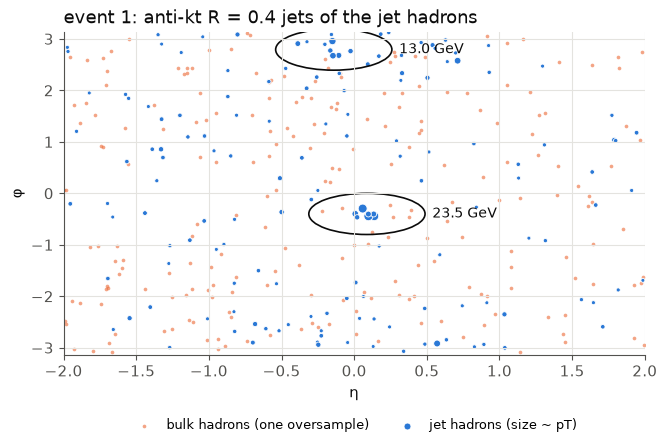

In [8]:
e = int(np.argmax(lead_jet))
b, j = bulk_had[e, 0], jets_had[e]
b, j = b[abs(b.eta) < 2], j[abs(j.eta) < 2]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.scatter(ak.to_numpy(b.eta), ak.to_numpy(b.phi), s=7, color=ORANGE, alpha=0.6,
           linewidths=0, label="bulk hadrons (one oversample)")
ax.scatter(ak.to_numpy(j.eta), ak.to_numpy(j.phi), s=8 + 6 * ak.to_numpy(j.pt), color=BLUE,
           edgecolors="white", linewidths=0.6, label="jet hadrons (size ~ pT)")
for jet in jets_all[e]:
    ax.add_patch(plt.Circle((float(jet.eta), float(jet.phi)), 0.4, fill=False, color=INK,
                            lw=1.2))
    ax.annotate(f"{float(jet.pt):.1f} GeV", (float(jet.eta) + 0.45, float(jet.phi)),
                va="center", color=INK, fontsize=10)
ax.set_xlim(-2, 2)
ax.set_ylim(-np.pi, np.pi)
ax.set_xlabel("η")
ax.set_ylabel("φ")
ax.set_title(f"event {int(jet_h.info['units']['event'][e])}: anti-kt R = 0.4 jets of the "
             "jet hadrons", color=INK, loc="left")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2,
          fontsize=9)
plt.show()

## Where to go from here

- **Making the files**: `oo_workflow.ipynb` next to this notebook runs the events (it needs the
  X-SCAPE build with PyJetscape) and writes these two files to `out_oo/`.
- **More events**: the O+O production, `example/prod_OO_isr/README.md`; its campaigns are on
  the OSDF too (`./js_osdf.py ls` in `utils/remote_transfer`) and read exactly as here.
- **Many files**: download them (`js_osdf.py download <campaign> --what h5`) and read them
  with `HadronArray.from_h5(path, units=...)` per file, or `hadrons_h5.HadronFileReader` for
  whole campaigns; streaming pays for a file read once, a download for anything read again
  (`docs/README_analysis.md`, "Getting the files").